In [ ]:
#| default_exp pretrained

# Running a pretrained voice

> Kokoro-82M on the Mac, checked against what audio-reader asks of Alex.

This is the first notebook of the pretrained line: take a voice someone else trained and find out whether it can do
everything Alex does for audio-reader. Alex is the bar for *control* here, not for sound. Kokoro already sounds better.

## What audio-reader asks of Alex

audio-reader's `ArticlePlayer` drives `AVSpeechSynthesizer`. It never asks for a finished audio file. It hands the voice
one chunk at a time (a paragraph, or sentences packed up to 320 characters) and asks for five things:

| Control | How Alex does it | What a neural voice needs |
|---|---|---|
| Play, skip, seek | `speak()` the chunk at the new position | synthesise a chunk faster than it plays, and start quickly |
| Follow the words | a `willSpeakRange` callback per word | where every word starts and ends, in samples and in the text |
| Pause | `pauseSpeaking(at: .word)` | the end of the current word |
| Resume | `continueSpeaking()` | keep the audio we already made |
| Speed, 0.5x to 3x | `utterance.rate`: the voice itself talks faster | a speed control inside the model |

That last row is a lesson audio-reader learnt the hard way: it used to time-stretch rendered audio, and fast speech
came out smeared. Now it restarts the chunk at the new rate. We want the same: speed from the model, not from DSP.

## Kokoro

[Kokoro-82M](https://huggingface.co/hexgrad/Kokoro-82M) is a StyleTTS 2 descendant with Apache-licensed weights. It
turns text into phonemes with a separate frontend (misaki), predicts a *duration* for every phoneme, then renders all
of them at once and finishes with an iSTFT-based vocoder. Those durations are the reason to pick it: they say where
every word is, and the speed knob simply divides them.

In [ ]:
#| export
import difflib
import re

import librosa
import numpy as np
import pandas as pd
import torch
from kokoro import KPipeline
from transformers import pipeline as hf_pipeline

In [ ]:
import time

import matplotlib.pyplot as plt
from IPython.display import Audio, display

from text_to_speech.data import metadata

In [ ]:
#| export
SR = 24_000  # Kokoro's sample rate
pipeline = KPipeline(lang_code="a", repo_id="hexgrad/Kokoro-82M", device="cpu")  # "a": American English

/Users/henrydashwood/text-to-speech/.venv/lib/python3.13/site-packages/torch/nn/modules/rnn.py:1011: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)
/Users/henrydashwood/text-to-speech/.venv/lib/python3.13/site-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
/Users/henrydashwood/text-to-speech/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [ ]:
print(f"{sum(p.numel() for p in pipeline.model.parameters()) / 1e6:.0f}M parameters")

82M parameters


In [ ]:
#| export
pipelines = {"a": pipeline}


def say(text, speed=1, voice="af_heart"):
    "Synthesise `text` as a single chunk. Kokoro's result has the phonemes, the audio and a token per word."
    lang = voice[0]  # A voice's first letter is its language: "a" American English, "b" British, ...
    if lang not in pipelines:  # Each language has its own frontend, all sharing the one model
        pipelines[lang] = KPipeline(lang_code=lang, repo_id="hexgrad/Kokoro-82M", model=pipeline.model)
    (result,) = pipelines[lang](text, voice=voice, speed=speed, split_pattern=None)
    return result

In [ ]:
r = say("Hello there. This is Kokoro, reading aloud on a laptop.")
print(r.phonemes)
Audio(r.audio, rate=SR)

həlˈO ðˈɛɹ. ðˌɪs ɪz kəkˈɔɹO, ɹˈidɪŋ əlˈWd ˌɔn ɐ lˈæptˌɑp.


## Fast enough?

Two numbers matter. How many times faster than real time, which has to be well above 1 to survive the move to a phone.
And how long until the first sound, which is what pressing play or seeking feels like. Kokoro renders a whole chunk at
once, so the first sound waits for the whole chunk.

In [ ]:
chunk = (
    "Long paragraphs are split so pause and seek stay responsive. A synthesiser can only stop cleanly between "
    "utterances or at word boundaries, so the reader hands it one chunk at a time, each a few sentences long, and "
    "follows along word by word as it speaks."
)
say("Warm up.")
for text in [chunk.split(". ")[0] + ".", chunk]:
    t = time.time()
    audio = say(text).audio
    elapsed = time.time() - t
    print(
        f"{len(text):>3} characters: {elapsed:.2f}s to make {len(audio) / SR:4.1f}s of audio, "
        f"{len(audio) / SR / elapsed:.0f}x real time"
    )

 60 characters: 0.80s to make  4.2s of audio, 5x real time
254 characters: 3.37s to make 16.9s of audio, 5x real time


Comfortably faster than real time on the CPU. (The GPU is no faster: at this size the model is too small to keep it
busy.) But a full 320-character chunk takes a couple of seconds before any sound, while its first sentence alone is
much quicker. So a player should synthesise the first sentence of a chunk on its own and render the rest while it
plays. A phone will be several times slower than this laptop, so that margin matters.

## Where are the words?

misaki gives one token per word, and Kokoro adds up the predicted durations of each word's phonemes into start and end
times. That's the `willSpeakRange` callback, available before playback starts rather than as it happens. We also need
each word's position in the text, to highlight it on screen and to save a reading position.

In [ ]:
#| export
def word_spans(text, tokens):
    "One row per token: its text, where it is in `text`, and when it is spoken."
    rows, i = [], 0
    for t in tokens:
        i = text.index(t.text, i)
        rows.append((t.text, i, i + len(t.text), t.start_ts, t.end_ts))
        i += len(t.text)
    return pd.DataFrame(rows, columns=["text", "char_start", "char_end", "start", "end"])

In [ ]:
text = "Doctor Smith paid $12.50 for 3 books on 1/2/2024, didn't she?"
r = say(text)
words = word_spans(text, r.tokens)
words

,text,char_start,char_end,start,end
0,Doctor,0,6,0.2750,0.6750
1,Smith,7,12,0.6750,1.0250
2,paid,13,17,1.0250,1.2750
3,$,18,19,NaN,NaN
4,12.50,19,24,1.2750,3.1250
5,for,25,28,3.1250,3.3125
6,3,29,30,3.3125,3.5500
7,books,31,36,3.5500,3.7875
8,on,37,39,3.7875,3.9250
9,1/2/2024,40,48,3.9250,5.6750


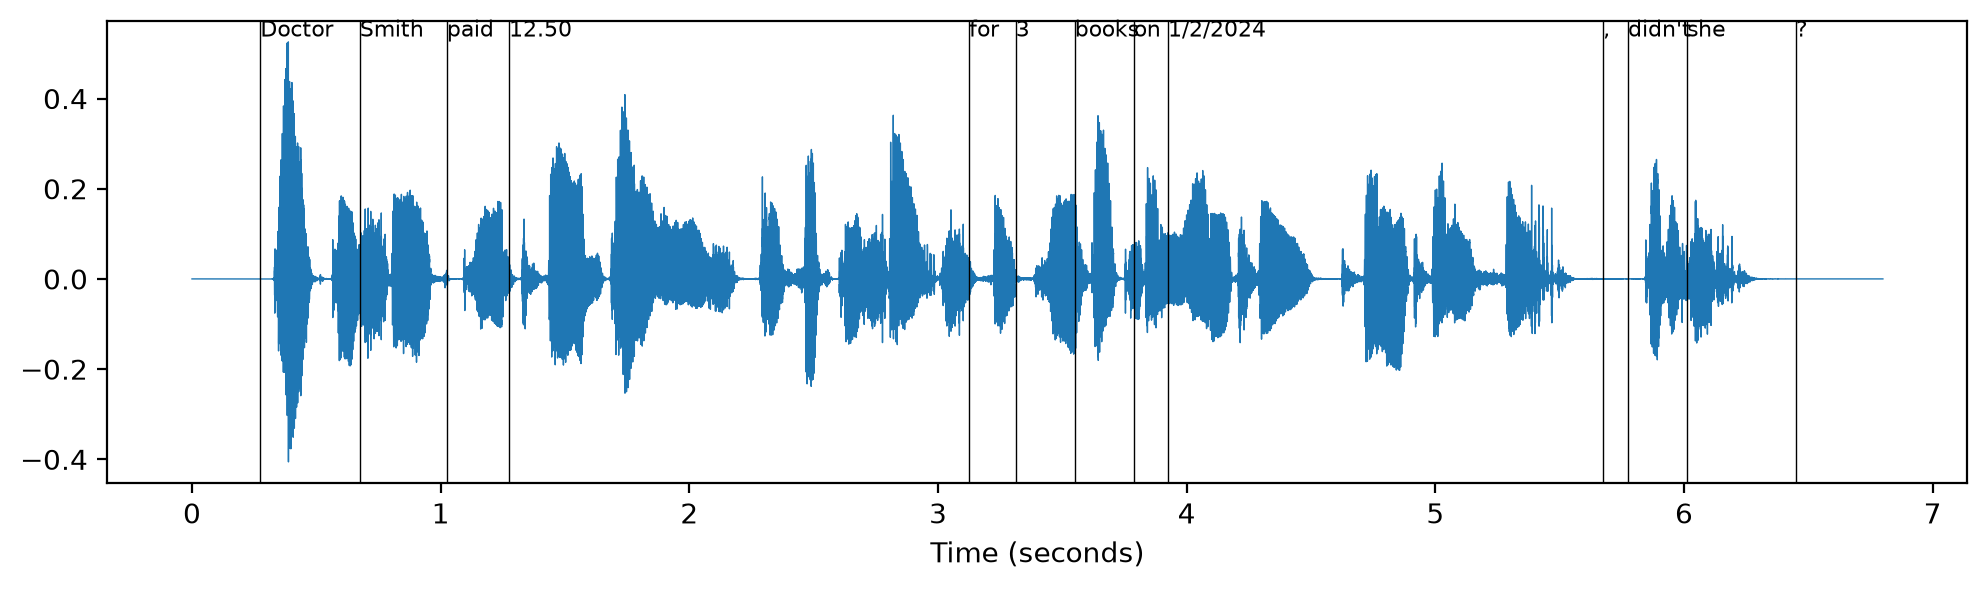

In [ ]:
audio = r.audio.numpy()
plt.figure(figsize=(12, 3))
plt.plot(np.arange(len(audio)) / SR, audio, lw=0.5)
for w in words.dropna().itertuples():
    plt.axvline(w.start, color="k", lw=0.5)
    plt.text(w.start, audio.max(), w.text, fontsize=8, va="bottom")
plt.xlabel("Time (seconds)")
plt.show()

Cutting the audio at a word's timestamps should give exactly that word:

In [ ]:
w = words.set_index("text").loc["books"]
Audio(audio[int(w.start * SR) : int(w.end * SR)], rate=SR)

Two things to notice in the table. `$` has no time of its own: the frontend read `$12.50` as "twelve dollars and
fifty cents" and gave all of it to `12.50`. A player can highlight the two together. And `1/2/2024` comes out as "one
two twenty twenty four". That's the frontend, not the voice, and it's a reminder that text normalisation is its own
problem. Alex has decades of rules for it.

## Speed

`speed` divides every predicted duration before rendering, so in principle the voice itself talks faster and the word
timestamps stay true. Listen, though: at 2x and 3x sounds go missing all through the sentence.

In [ ]:
text = "Speed comes from the voice itself, not from stretching the audio afterwards."
for speed in [0.5, 1, 2, 3]:
    r = say(text, speed)
    last = max(t.end_ts for t in r.tokens if t.end_ts)
    print(f"{speed}x: {len(r.audio) / SR:.2f}s of audio, last word ends at {last:.2f}s")
    display(Audio(r.audio, rate=SR))

0.5x: 9.57s of audio, last word ends at 9.45s
1x: 4.83s of audio, last word ends at 4.72s
2x: 2.55s of audio, last word ends at 2.45s
3x: 2.17s of audio, last word ends at 2.08s


### Why sounds go missing

Kokoro rounds each phoneme's duration to a whole number of frames, 600 samples (25 ms) each, and never fewer than one.
`pred_dur` holds those frame counts. `<` and `>` are the silences before and after the speech, and stress marks get
frames of their own.

In [ ]:
r1, r2 = say(text), say(text, 2)
frames = pd.DataFrame(
    {
        "phoneme": ["<", *[p for p in r1.phonemes if p in pipeline.model.vocab], ">"],
        "1x": r1.pred_dur,
        "2x": r2.pred_dur,
    }
)
print(f"{frames['1x'].mean():.1f} frames per phoneme at 1x, and {(frames['2x'] == 1).mean():.0%} get just one at 2x")
frames.head(32).T

2.5 frames per phoneme at 1x, and 86% get just one at 2x


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
phoneme,<,s,p,ˈ,i,d,,k,ˈ,ʌ,m,z,,f,ɹ,ʌ,m,,ð,ə,,v,ˈ,Y,s,,ɪ,t,s,ˈ,ɛ,l
1x,14,3,2,3,3,2,2,2,2,2,2,2,1,1,1,1,1,1,1,1,2,2,3,3,2,2,2,3,3,3,3,3
2x,7,1,1,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,2,1,1,1,1,2,1,2,1,2


At 1x a phoneme gets two or three frames. At 2x nearly every phoneme gets exactly one, and the ones that should get
one and a half are rounded *down*: the /s/ of "speed", the vowel of "voice", the /ʧ/ of "stretching". A single 25 ms
frame is one feature vector, and the decoder's convolutions blur it into its neighbours, so short consonants vanish.
It's also why 3x is barely shorter than 2x: almost everything is already at the floor. And the silence before the
speech halves too, which takes the start of the first word with it.

### Counting what's lost

Ears are the judge, but to compare fixes we want a number. So we transcribe with Whisper and count the fraction of
words it hears, in order. Whisper also struggles with an abrupt start, so we pad the audio with silence first.

To try other retimings we need the one line of Kokoro that applies `speed`. `render` is Kokoro's own
`forward_with_tokens` with that line, `round(duration / speed).clamp(min=1)`, passed in as `retime`.

In [ ]:
#| export
model = pipeline.model


@torch.no_grad()
def render(phonemes, retime, voice="af_heart"):
    "Kokoro's `forward_with_tokens`, with the rounding of durations to frames done by `retime`."
    ref_s = pipeline.load_voice(voice)[len(phonemes) - 1]
    ids = torch.LongTensor([[0, *[model.vocab[p] for p in phonemes if p in model.vocab], 0]])
    n = ids.shape[1]
    lengths, mask = torch.tensor([n]), torch.zeros(1, n, dtype=torch.bool)
    s = ref_s[:, 128:]
    bert = model.bert_encoder(model.bert(ids, attention_mask=(~mask).int())).transpose(-1, -2)
    d = model.predictor.text_encoder(bert, s, lengths, mask)
    duration = torch.sigmoid(model.predictor.duration_proj(model.predictor.lstm(d)[0])).sum(-1).squeeze()  # In frames
    frames = retime(duration)
    aln = torch.zeros(1, n, int(frames.sum()))  # Which phoneme each frame belongs to
    aln[0, torch.repeat_interleave(torch.arange(n), frames), torch.arange(int(frames.sum()))] = 1
    F0, N = model.predictor.F0Ntrain(d.transpose(-1, -2) @ aln, s)
    return model.decoder(model.text_encoder(ids, lengths, mask) @ aln, F0, N, ref_s[:, :128]).squeeze().numpy()


def kokoro_speed(speed):
    return lambda duration: torch.round(duration / speed).clamp(min=1).long()


def keep_lead_in(speed):
    "Kokoro's speed, except the silences before and after the speech keep their 1x length."

    def retime(duration):
        frames = kokoro_speed(speed)(duration)
        frames[[0, -1]] = torch.round(duration[[0, -1]]).long()
        return frames

    return retime

In [ ]:
len(render(r2.phonemes, kokoro_speed(2))) == len(r2.audio)

True

In [ ]:
#| export
whisper = hf_pipeline("automatic-speech-recognition", model="openai/whisper-small.en")


def heard(audio):
    "What Whisper hears, with half a second of silence either side."
    audio = librosa.resample(np.pad(audio, SR // 2), orig_sr=SR, target_sr=16_000)
    return whisper({"raw": audio, "sampling_rate": 16_000})["text"]


def words(t):
    return re.sub(r"[^a-z' ]", " ", t.lower()).split()


def recall(text, audio):
    "Fraction of the words in `text` that Whisper hears, in order."
    blocks = difflib.SequenceMatcher(a=words(text), b=words(heard(audio)), autojunk=False).get_matching_blocks()
    return sum(b.size for b in blocks) / len(words(text))


Loading weights: 100%|##########| 479/479 [00:00<00:00, 8245.25it/s]


Four ways to go faster, on our sentence and nine held-out LJSpeech transcripts. Two of them time-stretch, which keeps
pitch and squeezes the waveform after rendering: on its own, and on top of Kokoro at 1.3x, where few phonemes are
rounded down yet. Whisper can't follow even clean 3x speech, so we stop at 2x.

In [ ]:
texts = [text, *[t for t in metadata().query("id.str.startswith('LJ050')").normalized_text if len(t) < 200][:9]]
phonemes = [say(t).phonemes for t in texts]
normal = [render(ps, kokoro_speed(1)) for ps in phonemes]


def stretched(speed, model_speed=1):
    "Kokoro at `model_speed`, then time-stretched to exactly `1 / speed` of the 1x length."
    out = []
    for ps, slow in zip(phonemes, normal):
        fast = render(ps, keep_lead_in(model_speed))
        out.append(librosa.effects.time_stretch(fast, rate=len(fast) * speed / len(slow)))
    return out


rows = [(1, "Kokoro", 1, np.mean([recall(t, a) for t, a in zip(texts, normal)]))]
for speed in [1.5, 2]:
    methods = {
        "Kokoro's speed": [render(ps, kokoro_speed(speed)) for ps in phonemes],
        "Kokoro's speed, keeping the lead-in": [render(ps, keep_lead_in(speed)) for ps in phonemes],
        "time-stretch": stretched(speed),
        "Kokoro at 1.3x, then time-stretch": stretched(speed, 1.3),
    }
    for name, audios in methods.items():
        actual = sum(map(len, normal)) / sum(map(len, audios))
        rows.append((speed, name, actual, np.mean([recall(t, a) for t, a in zip(texts, audios)])))
    if speed == 2:
        for name, audios in methods.items():
            print(name)
            display(Audio(audios[0], rate=SR))
pd.DataFrame(rows, columns=["speed", "method", "actual speed", "word recall"]).round(2)

Kokoro's speed
Kokoro's speed, keeping the lead-in
time-stretch
Kokoro at 1.3x, then time-stretch


/Users/henrydashwood/text-to-speech/.venv/lib/python3.13/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/Users/henrydashwood/text-to-speech/.venv/lib/python3.13/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/Users/henrydashwood/text-to-speech/.venv/lib/python3.13/site-packages/numba/np/ufunc/dufunc.py:303: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


,speed,method,actual speed,word recall
0,1.0,Kokoro,1.00,0.98
1,1.5,Kokoro's speed,1.56,0.88
2,1.5,"Kokoro's speed, keeping the lead-in",1.51,0.94
3,1.5,time-stretch,1.50,0.97
4,1.5,"Kokoro at 1.3x, then time-stretch",1.50,0.94
5,2.0,Kokoro's speed,1.84,0.75
6,2.0,"Kokoro's speed, keeping the lead-in",1.73,0.88
7,2.0,time-stretch,2.00,0.81
8,2.0,"Kokoro at 1.3x, then time-stretch",2.00,0.83


Keeping the lead-in is the one clear win: it brings the first word back and fixes most of the damage at 1.5x, for
free. What's left is the frame grid, and at 2x it still loses a word in eight. Past that, nothing here beats a plain
time-stretch by more than a word across these ten sentences, which is noise. But the time-stretch here is librosa's
phase vocoder, and notebook 101 finds it is the worst of the real stretchers: it smears, which is what audio-reader heard. With
Sonic instead, Whisper hears every word at 2x that it hears at 1x.

Two other retimings did worse, so they aren't here. Fractional durations, sharing a frame between neighbouring
phonemes, sound worse than rounding (a third of words lost at 2x): the decoder never saw blended frames in training.
Protecting short phonemes by squeezing long ones harder never gets past about 1.4x, and loses more words on the way.

The lesson for the from-scratch line is about frame rate. At 1x this voice says about 16 phonemes a second, so 3x is
about 50. A model that must speak at 3x needs comfortably more than 50 frames a second. Kokoro has 40. Our mel
spectrogram, at a hop of 256 samples, has 86.

## Summary

| Control | Kokoro on this laptop |
|---|---|
| Play, skip, seek | fast enough, but the first sound waits for the whole chunk: synthesise the first sentence on its own |
| Follow the words | yes: a start and end time for every word, before playback |
| Pause | we hold the audio and know where the current word ends, so stop there |
| Resume | carry on from the same sample |
| Speed | Kokoro's own speed drops sounds from 1.5x: 25 ms frames are too coarse. Render at 1x and speed up with Sonic instead (notebook 101) |

Nearly everything needed for control is there. What's missing is a player that uses it.

## Next

- **101**: a better time-stretch than librosa's phase vocoder, for the speeds Kokoro can't do.
- **102**: that player. A `sounddevice` output stream we feed ourselves, with play, pause at the word, seek, skip
  and speed changes, driven by these timestamps, on the same chunks audio-reader makes.
- Then the same player on a phone: Kokoro exported to Core ML and to an Android runtime, checking that speed, timing
  and quality survive the trip.

## Things to try

- Try other voices (`af_bella`, `am_michael`, `bf_emma`, ...). Is the speed range as clean for all of them?
- Find more text the frontend gets wrong: times, ordinals, abbreviations, URLs. Which of them does Alex get right?
- Change the speed by 10% at a time between 0.5x and 3x. Where does it stop sounding natural?
- Move the split between Kokoro and time-stretching: 1.1x, 1.5x, 1.7x of model speed. Where do your ears put it?
- Give every phoneme at least two frames at 2x and let the lead-in and pauses absorb the rest. How fast can it go?